Loading images...

[TASK 1] Filtering Foundations
  Kernel size rule: radius = ceil(3σ) -> captures 99.73% of Gaussian mass.

  [1c] Separability speedup (2D vs two 1D passes):
    σ=1.00 (kernel 7x7): speedup=2.98x, max|Δ|=9.16e-05
    σ=1.50 (kernel 11x11): speedup=6.45x, max|Δ|=9.16e-05
    σ=2.00 (kernel 13x13): speedup=13.37x, max|Δ|=2.29e-04
    σ=3.00 (kernel 19x19): speedup=15.86x, max|Δ|=2.14e-04
    σ=4.00 (kernel 25x25): speedup=18.90x, max|Δ|=2.14e-04

  [1d] Verification against OpenCV GaussianBlur:
    σ=1.0  ksize=7  max abs error vs OpenCV = 4.578e-05
    σ=2.0  ksize=13  max abs error vs OpenCV = 6.104e-05
    σ=4.0  ksize=25  max abs error vs OpenCV = 9.155e-05

[TASK 2] Detecting corners...
  Corners: checker=48, library=138, natural=350, foggy=5


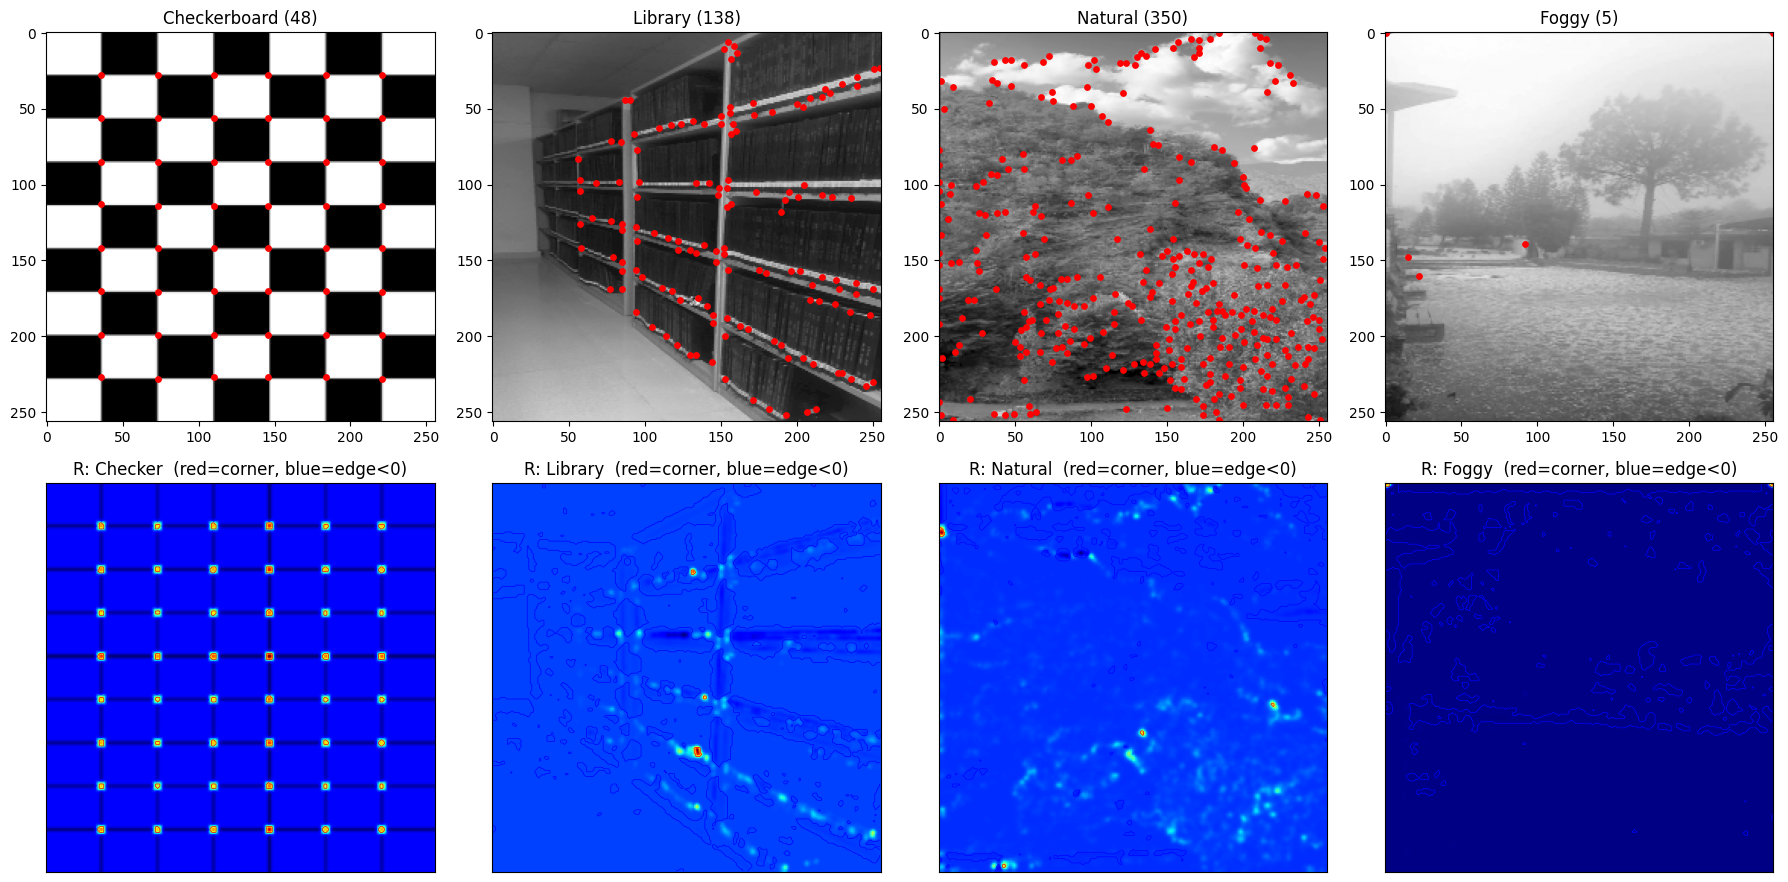


[TASK 3] Eigenvalue Analysis
  Max |det(M) - λ1λ2|   = 1.562e+00
  Max |trace(M) - λ1+λ2| = 4.883e-04

  R(λ1, λ2, k) = λ1·λ2 - k·(λ1 + λ2)^2
  Corner region requires R > 0  =>  λ2/λ1 >= r_min(k):
    k = 0.04 -> r_min = 0.0436
    k = 0.06 -> r_min = 0.0685


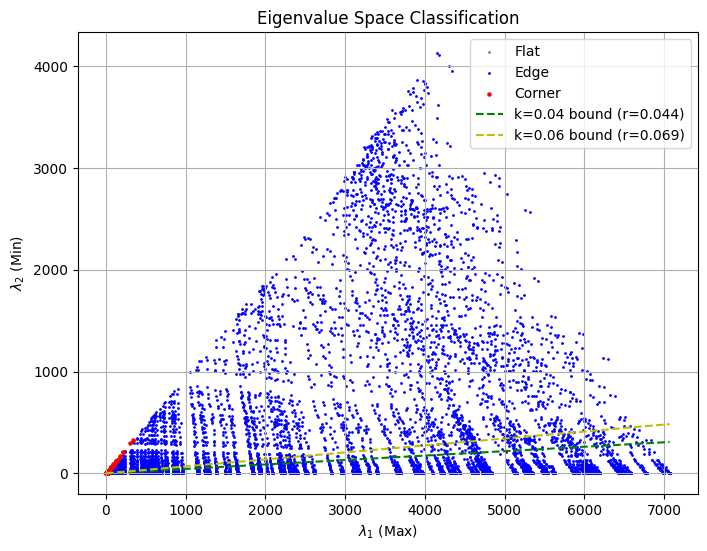


[TASK 4] Invariance sweeps (relative AND fixed thresholds)...
  Fixed absolute threshold = 41191.8633 (R units)


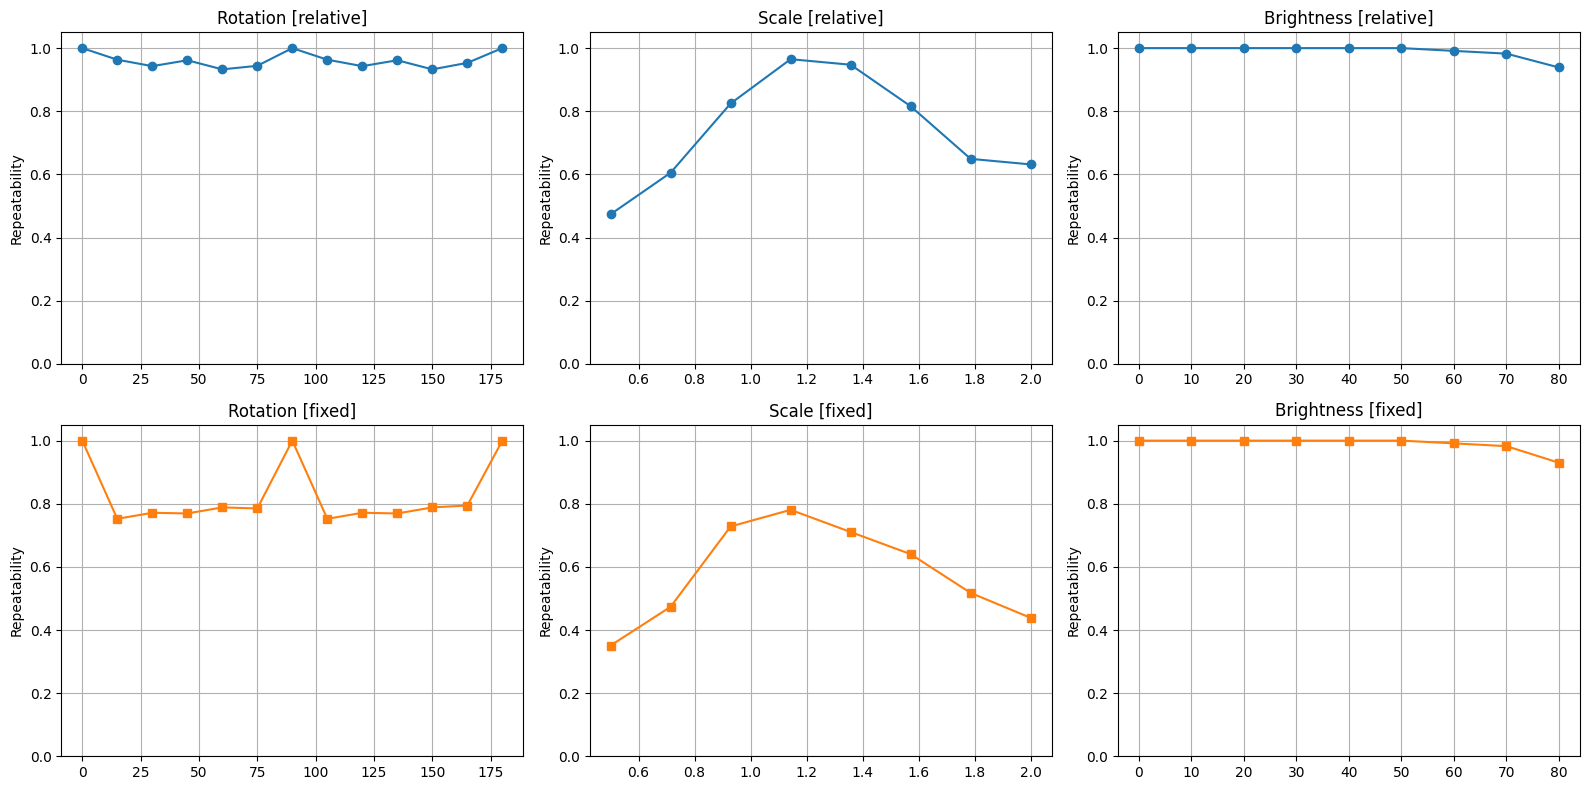

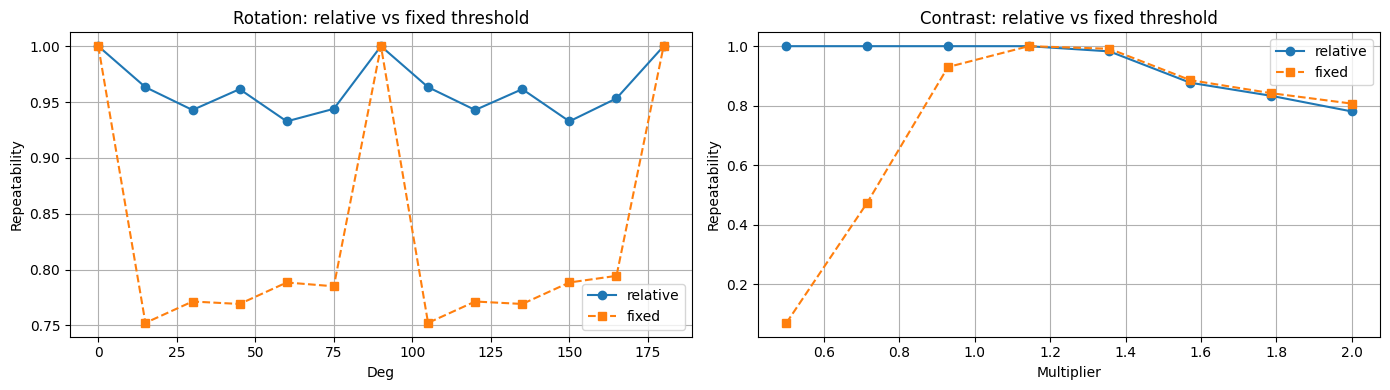

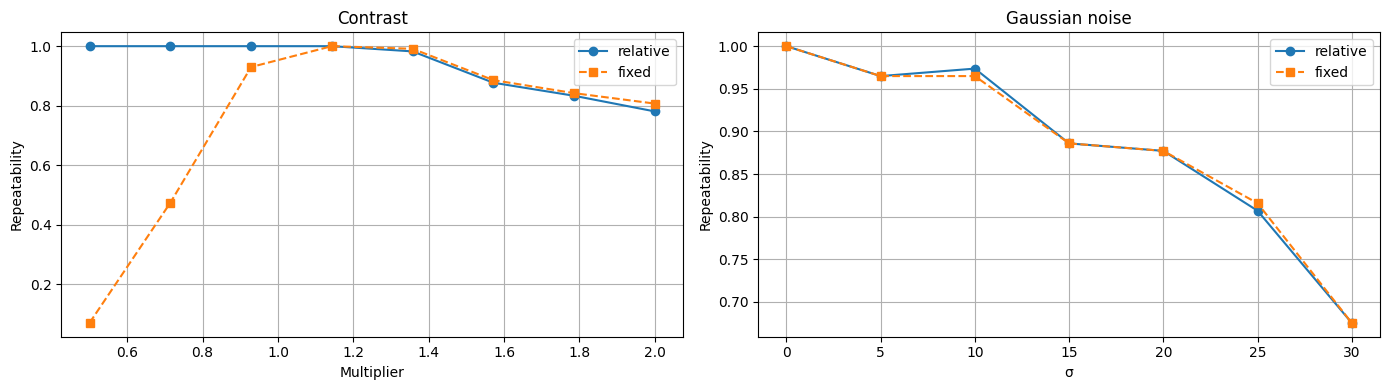


[TASK 5] Parameter Study & Comparison

  [5a] Corner counts over (σ, k, threshold), Gaussian vs Box:
  σ     k     thr     Gaussian  Box
  1.0   0.02  0.005   279       290
  1.0   0.02  0.01    241       248
  1.0   0.02  0.02    184       202
  1.0   0.02  0.05    84        96
  1.0   0.04  0.005   223       229
  1.0   0.04  0.01    188       204
  1.0   0.04  0.02    141       158
  1.0   0.04  0.05    75        80
  1.0   0.06  0.005   190       198
  1.0   0.06  0.01    164       156
  1.0   0.06  0.02    129       128
  1.0   0.06  0.05    73        69
  1.5   0.02  0.005   179       277
  1.5   0.02  0.01    161       256
  1.5   0.02  0.02    138       227
  1.5   0.02  0.05    83        164
  1.5   0.04  0.005   156       272
  1.5   0.04  0.01    138       239
  1.5   0.04  0.02    114       200
  1.5   0.04  0.05    69        130
  1.5   0.06  0.005   141       204
  1.5   0.06  0.01    128       177
  1.5   0.06  0.02    106       161
  1.5   0.06  0.05    62        107
 

In [8]:
# harris_corner_detector.py
# Computer Vision Assignment 1 — Harris Corner Detector

import numpy as np
import cv2
import matplotlib.pyplot as plt
import time
import os

# ==========================================================================
# TASK 1: FILTERING FOUNDATIONS
# ==========================================================================

def convolve2d(image, kernel, padding='reflect'):
    """2D convolution with odd kernel; supports 'zero' and 'reflect' padding."""
    image = np.asarray(image, dtype=np.float32)
    kernel = np.asarray(kernel, dtype=np.float32)
    kernel = np.flip(kernel)  # true convolution, not correlation

    kh, kw = kernel.shape
    assert kh % 2 == 1 and kw % 2 == 1, "Kernel size must be odd."

    ph, pw = kh // 2, kw // 2
    h, w = image.shape

    if padding == 'reflect':
        padded = np.pad(image, ((ph, ph), (pw, pw)), mode='reflect')
    elif padding == 'zero':
        padded = np.pad(image, ((ph, ph), (pw, pw)), mode='constant', constant_values=0)
    else:
        raise ValueError("Padding must be 'zero' or 'reflect'")

    output = np.zeros_like(image)
    for r in range(kh):
        for c in range(kw):
            output += padded[r:r + h, c:c + w] * kernel[r, c]
    return output


def convolve1d(image, kernel1d, axis=0, padding='reflect'):
    """1D separable convolution along rows (axis=1) or columns (axis=0)."""
    image = np.asarray(image, dtype=np.float32)
    kernel1d = np.asarray(kernel1d, dtype=np.float32).flatten()
    kernel1d = np.flip(kernel1d)

    k_len = len(kernel1d)
    p = k_len // 2
    h, w = image.shape

    if axis == 0:
        padded = np.pad(image, ((p, p), (0, 0)), mode=padding)
        output = np.zeros_like(image)
        for r in range(k_len):
            output += padded[r:r + h, :] * kernel1d[r]
    else:
        padded = np.pad(image, ((0, 0), (p, p)), mode=padding)
        output = np.zeros_like(image)
        for c in range(k_len):
            output += padded[:, c:c + w] * kernel1d[c]
    return output


def separable_gaussian_filter(image, kernel_x, kernel_y, padding='reflect'):
    temp = convolve1d(image, kernel_x, axis=1, padding=padding)
    return convolve1d(temp, kernel_y, axis=0, padding=padding)


def get_gaussian_kernel(sigma):
    """
    Build a normalized 1D Gaussian kernel.
    radius = ceil(3*sigma) captures 99.73% of the Gaussian mass (±3σ);
    beyond this the weights are < 0.3% and negligible.
    """
    radius = int(np.ceil(3 * sigma))
    x = np.arange(-radius, radius + 1, dtype=np.float32)
    kernel = np.exp(-0.5 * (x / sigma) ** 2)
    kernel /= kernel.sum()
    return kernel


sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32) / 8.0
sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32) / 8.0

central_diff_x = np.array([[0, 0, 0], [-0.5, 0, 0.5], [0, 0, 0]], dtype=np.float32)
central_diff_y = np.array([[0, -0.5, 0], [0, 0, 0], [0, 0.5, 0]], dtype=np.float32)


def derivative_of_gaussian_kernels(sigma):
    """Derivative-of-Gaussian (DoG) gradient kernels."""
    r = int(np.ceil(3 * sigma))
    x = np.arange(-r, r + 1, dtype=np.float32)
    g = np.exp(-0.5 * (x / sigma) ** 2)
    g /= g.sum()
    dg = (-x / (sigma ** 2)) * g
    kx = np.outer(g, dg)
    ky = np.outer(dg, g)
    kx /= np.max(np.abs(kx))
    ky /= np.max(np.abs(ky))
    return kx.astype(np.float32), ky.astype(np.float32)


# ==========================================================================
# LOADING IMAGES
# ==========================================================================

def load_image_safely(filename):
    paths = [f"/content/{filename}", f"./{filename}", f"/content/drive/MyDrive/{filename}"]
    for p in paths:
        if os.path.exists(p):
            img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                return cv2.resize(img, (256, 256)).astype(np.float32)
    raise FileNotFoundError(f"Could not find {filename}. Please upload it to Colab.")


print("Loading images...")
img_checkerboard = load_image_safely('CHECKERBOARD.png')
img_structured   = load_image_safely('LIBRARY.png')
img_textured     = load_image_safely('NATURAL.png')
img_low_contrast = load_image_safely('FOGGY.png')

# ==========================================================================
# TASK 1 VERIFICATION
# ==========================================================================
print("\n[TASK 1] Filtering Foundations")
print("  Kernel size rule: radius = ceil(3σ) -> captures 99.73% of Gaussian mass.")

print("\n  [1c] Separability speedup (2D vs two 1D passes):")
for sig in [1.0, 1.5, 2.0, 3.0, 4.0]:
    g_1d = get_gaussian_kernel(sig)
    g_2d = np.outer(g_1d, g_1d)

    t0 = time.time(); res_2d = convolve2d(img_checkerboard, g_2d); t2d = time.time() - t0
    t0 = time.time(); res_1d = separable_gaussian_filter(img_checkerboard, g_1d, g_1d); t1d = time.time() - t0

    print(f"    σ={sig:.2f} (kernel {len(g_1d)}x{len(g_1d)}): "
          f"speedup={t2d/t1d:.2f}x, max|Δ|={np.max(np.abs(res_2d - res_1d)):.2e}")

print("\n  [1d] Verification against OpenCV GaussianBlur:")
for sig in [1.0, 2.0, 4.0]:
    g_1d = get_gaussian_kernel(sig)
    ours = separable_gaussian_filter(img_checkerboard, g_1d, g_1d)
    ksize = 2 * int(np.ceil(3 * sig)) + 1
    ref = cv2.GaussianBlur(img_checkerboard, (ksize, ksize), sig)
    err = np.max(np.abs(ours - ref))
    print(f"    σ={sig:.1f}  ksize={ksize}  max abs error vs OpenCV = {err:.3e}")

# ==========================================================================
# TASK 2 & 3: HARRIS DETECTOR IMPLEMENTATION
# ==========================================================================

def harris_corner_detector(image, k=0.04, sigma=1.0, threshold_ratio=0.01,
                           window_type='gaussian', gradient='sobel',
                           return_tensor=False):
    if gradient == 'sobel':
        kx, ky = sobel_x, sobel_y
    elif gradient == 'central':
        kx, ky = central_diff_x, central_diff_y
    elif gradient == 'dog':
        kx, ky = derivative_of_gaussian_kernels(sigma)
    else:
        raise ValueError("gradient must be 'sobel', 'central', or 'dog'")

    Ix = convolve2d(image, kx, padding='reflect')
    Iy = convolve2d(image, ky, padding='reflect')

    Ix2, Iy2, Ixy = Ix * Ix, Iy * Iy, Ix * Iy

    if window_type == 'gaussian':
        g_kernel = get_gaussian_kernel(sigma)
        Sxx = separable_gaussian_filter(Ix2, g_kernel, g_kernel)
        Syy = separable_gaussian_filter(Iy2, g_kernel, g_kernel)
        Sxy = separable_gaussian_filter(Ixy, g_kernel, g_kernel)
    else:
        box_size = int(np.ceil(3 * sigma)) * 2 + 1
        box_kernel = np.ones((box_size, box_size), dtype=np.float32) / (box_size ** 2)
        Sxx = convolve2d(Ix2, box_kernel)
        Syy = convolve2d(Iy2, box_kernel)
        Sxy = convolve2d(Ixy, box_kernel)

    det_M   = Sxx * Syy - Sxy ** 2
    trace_M = Sxx + Syy
    R = det_M - k * (trace_M ** 2)

    h, w = R.shape
    padded_R = np.pad(R, 1, mode='constant', constant_values=-np.inf)
    is_max = np.ones_like(R, dtype=bool)
    for dr in [-1, 0, 1]:
        for dc in [-1, 0, 1]:
            if dr == 0 and dc == 0:
                continue
            is_max &= (R >= padded_R[1+dr:1+dr+h, 1+dc:1+dc+w])

    max_r = np.max(R)
    threshold = threshold_ratio * max_r if max_r > 0 else 0
    corners = is_max & (R > threshold)
    corner_pts = np.argwhere(corners)

    if return_tensor:
        return corner_pts, R, Sxx, Syy, Sxy
    return corner_pts, R


print("\n[TASK 2] Detecting corners...")
pts_checker, R_checker, Sxx_c, Syy_c, Sxy_c = harris_corner_detector(
    img_checkerboard, k=0.04, sigma=1.5, return_tensor=True)
pts_struct, R_struct = harris_corner_detector(img_structured, k=0.04, sigma=1.5)
pts_text,   R_text   = harris_corner_detector(img_textured, k=0.04, sigma=1.5, threshold_ratio=0.02)
pts_low,    R_low    = harris_corner_detector(img_low_contrast, k=0.04, sigma=1.5, threshold_ratio=0.01)

print(f"  Corners: checker={len(pts_checker)}, library={len(pts_struct)}, "
      f"natural={len(pts_text)}, foggy={len(pts_low)}")


def r_label_overlay(ax, R, title):
    ax.imshow(R, cmap='jet')
    corner_m = R > 0.5 * np.max(R)
    edge_m   = (R < 0.0)
    ax.contour(corner_m, levels=[0.5], colors='red',  linewidths=0.5)
    ax.contour(edge_m,   levels=[0.5], colors='blue', linewidths=0.5)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])


fig, axs = plt.subplots(2, 4, figsize=(18, 9))
axs[0, 0].imshow(img_checkerboard, cmap='gray'); axs[0, 0].scatter(pts_checker[:, 1], pts_checker[:, 0], c='red', s=15); axs[0, 0].set_title(f"Checkerboard ({len(pts_checker)})")
axs[0, 1].imshow(img_structured, cmap='gray');   axs[0, 1].scatter(pts_struct[:, 1], pts_struct[:, 0], c='red', s=15);   axs[0, 1].set_title(f"Library ({len(pts_struct)})")
axs[0, 2].imshow(img_textured, cmap='gray');     axs[0, 2].scatter(pts_text[:, 1], pts_text[:, 0], c='red', s=15);       axs[0, 2].set_title(f"Natural ({len(pts_text)})")
axs[0, 3].imshow(img_low_contrast, cmap='gray'); axs[0, 3].scatter(pts_low[:, 1], pts_low[:, 0], c='red', s=15);         axs[0, 3].set_title(f"Foggy ({len(pts_low)})")
for i, (R, title) in enumerate(zip([R_checker, R_struct, R_text, R_low],
                                   ["Checker", "Library", "Natural", "Foggy"])):
    r_label_overlay(axs[1, i], R, f"R: {title}  (red=corner, blue=edge<0)")
plt.tight_layout()
plt.savefig("task2_corners_and_R.png", dpi=120)
plt.show()
plt.close()

# ==========================================================================
# TASK 3: EIGENVALUE ANALYSIS
# ==========================================================================
print("\n[TASK 3] Eigenvalue Analysis")
trace = Sxx_c + Syy_c
det   = Sxx_c * Syy_c - Sxy_c ** 2
disc  = np.clip((trace / 2.0) ** 2 - det, 0, None)
l1 = (trace / 2.0) + np.sqrt(disc)
l2 = (trace / 2.0) - np.sqrt(disc)

print(f"  Max |det(M) - λ1λ2|   = {np.max(np.abs(det  - l1 * l2)):.3e}")
print(f"  Max |trace(M) - λ1+λ2| = {np.max(np.abs(trace - (l1 + l2))):.3e}")

r_min_k04 = ((1 - 2 * 0.04) - np.sqrt(1 - 4 * 0.04)) / (2 * 0.04)
r_min_k06 = ((1 - 2 * 0.06) - np.sqrt(1 - 4 * 0.06)) / (2 * 0.06)
print("\n  R(λ1, λ2, k) = λ1·λ2 - k·(λ1 + λ2)^2")
print("  Corner region requires R > 0  =>  λ2/λ1 >= r_min(k):")
print(f"    k = 0.04 -> r_min = {r_min_k04:.4f}")
print(f"    k = 0.06 -> r_min = {r_min_k06:.4f}")

flat_mask   = (l1 < 2.0) & (l2 < 2.0)
edge_mask   = ((l1 >= 2.0) | (l2 >= 2.0)) & (np.abs(l1 - l2) > 15.0)
corner_mask = (l1 >= 2.0) & (l2 >= 2.0) & (np.abs(l1 - l2) <= 15.0)

plt.figure(figsize=(8, 6))
plt.scatter(l1[flat_mask],   l2[flat_mask],   color='gray', s=1, label='Flat')
plt.scatter(l1[edge_mask],   l2[edge_mask],   color='blue', s=1, label='Edge')
plt.scatter(l1[corner_mask], l2[corner_mask], color='red',  s=5, label='Corner')
x_vals = np.linspace(0, np.max(l1), 100)
plt.plot(x_vals, x_vals * r_min_k04, 'g--', label=f'k=0.04 bound (r={r_min_k04:.3f})')
plt.plot(x_vals, x_vals * r_min_k06, 'y--', label=f'k=0.06 bound (r={r_min_k06:.3f})')
plt.xlabel(r'$\lambda_1$ (Max)'); plt.ylabel(r'$\lambda_2$ (Min)')
plt.title('Eigenvalue Space Classification')
plt.legend(); plt.grid(True)
plt.savefig("task3_eigenvalue_scatter.png", dpi=120)
plt.show(); plt.close()

# ==========================================================================
# TASK 4: INVARIANCE EXPERIMENTS
# ==========================================================================
print("\n[TASK 4] Invariance sweeps (relative AND fixed thresholds)...")

def evaluate_repeatability(img_b, transform_matrix, corners_a, corners_b):
    if len(corners_a) == 0 or len(corners_b) == 0:
        return 0.0
    homog_a = np.hstack([corners_a[:, [1, 0]], np.ones((len(corners_a), 1))])
    mapped_a = (transform_matrix @ homog_a.T).T
    h, w = img_b.shape
    valid = (mapped_a[:, 0] >= 0) & (mapped_a[:, 0] < w) & \
            (mapped_a[:, 1] >= 0) & (mapped_a[:, 1] < h)
    mapped_a = mapped_a[valid]
    if len(mapped_a) == 0:
        return 0.0
    b_xy = corners_b[:, [1, 0]]
    dists = np.linalg.norm(mapped_a[:, None, :2] - b_xy[None, :, :2], axis=2)
    return np.sum(np.min(dists, axis=1) <= 2) / len(mapped_a)


def get_corners_relative(img):
    pts, _ = harris_corner_detector(img, sigma=1.5, threshold_ratio=0.02)
    return pts


def get_corners_fixed(img, fixed_thresh):
    _, R = harris_corner_detector(img, sigma=1.5, threshold_ratio=0.0)
    m = np.max(R) if np.max(R) > 0 else 1e-9
    pts, _ = harris_corner_detector(img, sigma=1.5, threshold_ratio=fixed_thresh / m)
    return pts


base_img = img_structured

_, R_base = harris_corner_detector(base_img, sigma=1.5, threshold_ratio=0.0)
FIXED_THR = 0.02 * np.max(R_base)
print(f"  Fixed absolute threshold = {FIXED_THR:.4f} (R units)")

# Rotation
rots = list(range(0, 181, 15))
rep_rot_rel, rep_rot_fix = [], []
for deg in rots:
    M = cv2.getRotationMatrix2D((base_img.shape[1]/2, base_img.shape[0]/2), deg, 1.0)
    rot_img = cv2.warpAffine(base_img, M, (base_img.shape[1], base_img.shape[0]),
                             flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    a_rel = get_corners_relative(base_img); b_rel = get_corners_relative(rot_img)
    a_fix = get_corners_fixed(base_img, FIXED_THR); b_fix = get_corners_fixed(rot_img, FIXED_THR)
    rep_rot_rel.append(evaluate_repeatability(rot_img, M, a_rel, b_rel))
    rep_rot_fix.append(evaluate_repeatability(rot_img, M, a_fix, b_fix))

# Scale
scales = np.linspace(0.5, 2.0, 8)
rep_scale_rel, rep_scale_fix = [], []
for s in scales:
    h, w = base_img.shape
    sc_img = cv2.resize(base_img, (int(w * s), int(h * s)))
    S = np.array([[s, 0, 0], [0, s, 0], [0, 0, 1]])
    a_rel = get_corners_relative(base_img); b_rel = get_corners_relative(sc_img)
    a_fix = get_corners_fixed(base_img, FIXED_THR); b_fix = get_corners_fixed(sc_img, FIXED_THR)
    rep_scale_rel.append(evaluate_repeatability(sc_img, S, a_rel, b_rel))
    rep_scale_fix.append(evaluate_repeatability(sc_img, S, a_fix, b_fix))

# Brightness
brights = list(range(0, 81, 10))
rep_bright_rel, rep_bright_fix = [], []
for b in brights:
    br = np.clip(base_img + b, 0, 255).astype(np.float32)
    a_rel = get_corners_relative(base_img); b_rel = get_corners_relative(br)
    a_fix = get_corners_fixed(base_img, FIXED_THR); b_fix = get_corners_fixed(br, FIXED_THR)
    rep_bright_rel.append(evaluate_repeatability(br, np.eye(3), a_rel, b_rel))
    rep_bright_fix.append(evaluate_repeatability(br, np.eye(3), a_fix, b_fix))

# Contrast
contrasts = np.linspace(0.5, 2.0, 8)
rep_contrast_rel, rep_contrast_fix = [], []
for c in contrasts:
    ct = np.clip(base_img * c, 0, 255).astype(np.float32)
    a_rel = get_corners_relative(base_img); b_rel = get_corners_relative(ct)
    a_fix = get_corners_fixed(base_img, FIXED_THR); b_fix = get_corners_fixed(ct, FIXED_THR)
    rep_contrast_rel.append(evaluate_repeatability(ct, np.eye(3), a_rel, b_rel))
    rep_contrast_fix.append(evaluate_repeatability(ct, np.eye(3), a_fix, b_fix))

# Gaussian noise
rng = np.random.default_rng(42)
noise_sigmas = list(range(0, 31, 5))
rep_noise_rel, rep_noise_fix = [], []
for ns in noise_sigmas:
    noisy = np.clip(base_img + rng.normal(0, ns, base_img.shape), 0, 255).astype(np.float32)
    a_rel = get_corners_relative(base_img); b_rel = get_corners_relative(noisy)
    a_fix = get_corners_fixed(base_img, FIXED_THR); b_fix = get_corners_fixed(noisy, FIXED_THR)
    rep_noise_rel.append(evaluate_repeatability(noisy, np.eye(3), a_rel, b_rel))
    rep_noise_fix.append(evaluate_repeatability(noisy, np.eye(3), a_fix, b_fix))

fig, axs = plt.subplots(2, 3, figsize=(16, 8))
axs[0, 0].plot(rots,    rep_rot_rel,    'o-', color='C0'); axs[0, 0].set_title('Rotation [relative]')
axs[0, 1].plot(scales,  rep_scale_rel,  'o-', color='C0'); axs[0, 1].set_title('Scale [relative]')
axs[0, 2].plot(brights, rep_bright_rel, 'o-', color='C0'); axs[0, 2].set_title('Brightness [relative]')
axs[1, 0].plot(rots,    rep_rot_fix,    's-', color='C1'); axs[1, 0].set_title('Rotation [fixed]')
axs[1, 1].plot(scales,  rep_scale_fix,  's-', color='C1'); axs[1, 1].set_title('Scale [fixed]')
axs[1, 2].plot(brights, rep_bright_fix, 's-', color='C1'); axs[1, 2].set_title('Brightness [fixed]')
for a in axs.flat:
    a.grid(True); a.set_ylim(0, 1.05); a.set_ylabel('Repeatability')
plt.tight_layout()
plt.savefig("task4_part1_rot_scale_bright.png", dpi=120)
plt.show(); plt.close()

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(rots,      rep_rot_rel,      'o-',  label='relative')
axs[0].plot(rots,      rep_rot_fix,      's--', label='fixed')
axs[0].set_title('Rotation: relative vs fixed threshold'); axs[0].set_xlabel('Deg')
axs[0].set_ylabel('Repeatability'); axs[0].legend(); axs[0].grid(True)
axs[1].plot(contrasts, rep_contrast_rel, 'o-',  label='relative')
axs[1].plot(contrasts, rep_contrast_fix, 's--', label='fixed')
axs[1].set_title('Contrast: relative vs fixed threshold'); axs[1].set_xlabel('Multiplier')
axs[1].set_ylabel('Repeatability'); axs[1].legend(); axs[1].grid(True)
plt.tight_layout(); plt.savefig("task4_part2_rel_vs_fix.png", dpi=120); plt.show(); plt.close()

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(contrasts,    rep_contrast_rel, 'o-',  label='relative')
axs[0].plot(contrasts,    rep_contrast_fix, 's--', label='fixed')
axs[0].set_title('Contrast'); axs[0].set_xlabel('Multiplier')
axs[0].set_ylabel('Repeatability'); axs[0].legend(); axs[0].grid(True)
axs[1].plot(noise_sigmas, rep_noise_rel,    'o-',  label='relative')
axs[1].plot(noise_sigmas, rep_noise_fix,    's--', label='fixed')
axs[1].set_title('Gaussian noise'); axs[1].set_xlabel('σ')
axs[1].set_ylabel('Repeatability'); axs[1].legend(); axs[1].grid(True)
plt.tight_layout(); plt.savefig("task4_part3_contrast_noise.png", dpi=120); plt.show(); plt.close()

# ==========================================================================
# TASK 5: PARAMETER STUDY AND COMPARISON
# ==========================================================================
print("\n[TASK 5] Parameter Study & Comparison")

print("\n  [5a] Corner counts over (σ, k, threshold), Gaussian vs Box:")
print(f"  {'σ':<6}{'k':<6}{'thr':<8}{'Gaussian':<10}{'Box'}")
for s in [1.0, 1.5, 2.0]:
    for k_val in [0.02, 0.04, 0.06]:
        for thr in [0.005, 0.01, 0.02, 0.05]:
            pts_g, _ = harris_corner_detector(img_structured, k=k_val, sigma=s,
                                              threshold_ratio=thr, window_type='gaussian')
            pts_b, _ = harris_corner_detector(img_structured, k=k_val, sigma=s,
                                              threshold_ratio=thr, window_type='box')
            print(f"  {s:<6}{k_val:<6}{thr:<8}{len(pts_g):<10}{len(pts_b)}")

print("\n  Why Gaussian window is preferred:")
print("   • Smooth weights -> less aliasing near corners, more stable R map.")
print("   • Rotation-friendlier: no blocky axis-aligned bias like the box.")
print("   • Suppresses distant pixels exponentially (box weights all pixels equally).")

t0 = time.time()
c_custom, _ = harris_corner_detector(img_checkerboard, k=0.04, sigma=1.5)
t_custom = time.time() - t0

t0 = time.time()
R_cv = cv2.cornerHarris(np.uint8(img_checkerboard), 2, 3, 0.04)
thr_cv = 0.01 * R_cv.max()
c_cv = np.argwhere(R_cv > thr_cv)
t_cv = time.time() - t0


def match_pct(pts_a, pts_b, tol=2.0):
    if len(pts_a) == 0 or len(pts_b) == 0:
        return 0.0
    a = pts_a[:, [1, 0]].astype(np.float32)
    b = pts_b[:, [1, 0]].astype(np.float32)
    d = np.linalg.norm(a[:, None] - b[None], axis=2)
    return 100.0 * np.mean(d.min(axis=1) <= tol)


pct_c2cv = match_pct(c_custom, c_cv)
pct_cv2c = match_pct(c_cv, c_custom)
print(f"\n  [5b] Comparison vs cv2.cornerHarris:")
print(f"    Custom→CV within 2px: {pct_c2cv:.1f}%")
print(f"    CV→Custom within 2px: {pct_cv2c:.1f}%")
print(f"    Runtime: Custom = {t_custom*1000:.2f} ms | OpenCV = {t_cv*1000:.2f} ms")
print(f"    Custom count = {len(c_custom)} | CV count = {len(c_cv)}")
print("    Why OpenCV is faster: SIMD-vectorized C++, integral-image Sobel,")
print("    hand-tuned loop order, and inlined NMS — vs. Python-level kernel loops.")

# ==========================================================================
# BONUS: gradient operator comparison (Sobel vs central-diff vs DoG)
# ==========================================================================
print("\n[BONUS] Gradient operator comparison on CHECKERBOARD")
print(f"  {'Gradient':<10}{'#Corners':<10}{'%Localization vs Sobel'}")
ref_pts, _ = harris_corner_detector(img_checkerboard, k=0.04, sigma=1.5, gradient='sobel')
for g in ['sobel', 'central', 'dog']:
    pts, _ = harris_corner_detector(img_checkerboard, k=0.04, sigma=1.5, gradient=g)
    pct = match_pct(pts, ref_pts) if len(pts) else 0.0
    print(f"  {g:<10}{len(pts):<10}{pct:.1f}%")

print("\n[BONUS] Gradient operator repeatability under Gaussian noise:")
rng2 = np.random.default_rng(7)
for g in ['sobel', 'central', 'dog']:
    reps = []
    for ns in [0, 10, 20, 30]:
        noisy = np.clip(img_checkerboard + rng2.normal(0, ns, img_checkerboard.shape), 0, 255).astype(np.float32)
        a, _ = harris_corner_detector(img_checkerboard, k=0.04, sigma=1.5, gradient=g)
        b, _ = harris_corner_detector(noisy,            k=0.04, sigma=1.5, gradient=g)
        reps.append(evaluate_repeatability(noisy, np.eye(3), a, b))
    print(f"  {g:<10}  " + "  ".join(f"σ={ns}: {r:.2f}" for ns, r in zip([0, 10, 20, 30], reps)))

print("\nAll figures saved: task2_*, task3_*, task4_*.")
print("Done.")